# Entrega 3 — Chunking de manifestações longas

**Problema:** manifestações longas misturam vários fatos (a UPA lotada, a falta de maca, o raio-x quebrado, o
estacionamento sem vigia...). Indexadas como um único bloco, elas viram um vetor "médio" que não representa bem
nenhum desses fatos. Como vamos ver, parte do texto nem chega a ser lida pelo modelo.

**Roteiro**
1. Mostrar o problema concreto: o limite de 128 tokens do MiniLM/MPNet **descarta o final** das manifestações longas.
2. Dividir as 5 manifestações mais longas com o `RecursiveCharacterTextSplitter` do LangChain em três configurações de
   `(chunk_size, chunk_overlap)`, mais dois experimentos de controle.
3. Medir a coesão entre chunks consecutivos (efeito do overlap).
4. Avaliar qual configuração preserva melhor o sentido, com exemplos e um teste de busca.
5. Visualizar os chunks em 2D (PCA e t-SNE) e verificar se chunks da mesma manifestação ficam próximos.

In [1]:
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

import ouvidoria_core as oc

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 160)
oc.estilo_graficos()
FIGURAS = Path("figuras")
FIGURAS.mkdir(exist_ok=True)

df = oc.carregar_manifestacoes()
NOME_MODELO = oc.MODELO_PADRAO                 # MiniLM multilíngue
modelo = oc.carregar_modelo(NOME_MODELO)
tokenizador = modelo.tokenizer

longas = df.nlargest(5, "n_caracteres").sort_values("id").reset_index(drop=True)
longas[["id", "categoria_oficial", "n_caracteres"]]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 9792.19it/s]

,id,categoria_oficial,n_caracteres
0,M006,saúde,708
1,M015,educação,696
2,M024,meio ambiente,714
3,M034,segurança,707
4,M040,infraestrutura,689


## 1. Por que chunking é necessário: o modelo não lê o texto inteiro

O MiniLM multilíngue (e o MPNet) tem `max_seq_length = 128` tokens. O `sentence-transformers` **corta silenciosamente**
tudo o que passa disso. Vamos medir quanto de cada manifestação longa é descartado e qual trecho se perde.

In [2]:
LIMITE = modelo.max_seq_length                 # 128, incluindo os tokens especiais <s> e </s>
print(f"max_seq_length do modelo: {LIMITE} tokens")

def trecho_ignorado(texto):
    cod = tokenizador(texto, return_offsets_mapping=True, add_special_tokens=False)
    n_tokens = len(cod["input_ids"])
    cabem = LIMITE - 2                         # descontando os 2 tokens especiais
    if n_tokens <= cabem:
        return n_tokens, ""
    inicio_cortado = cod["offset_mapping"][cabem][0]
    return n_tokens, texto[inicio_cortado:]

linhas = []
for _, r in longas.iterrows():
    n_tokens, ignorado = trecho_ignorado(r.texto)
    linhas.append({"id": r.id, "caracteres": r.n_caracteres, "tokens": n_tokens,
                   "% do texto ignorado": 100 * len(ignorado) / len(r.texto), "trecho que o modelo NÃO lê": ignorado})
truncamento = pd.DataFrame(linhas).set_index("id")
truncamento.style.format({"% do texto ignorado": "{:.0f}%"})

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (167 > 128). Running this sequence through the model will result in indexing errors


max_seq_length do modelo: 128 tokens


,caracteres,tokens,% do texto ignorado,trecho que o modelo NÃO lê
id,,,,
M006,708,167,26%,", mas o aparelho estava quebrado e tivemos que ir a um laboratório particular. Na volta, já de madrugada, o estacionamento estava sem iluminação e sem nenhum vigia. Exijo providências."
M015,696,156,20%,"Além disso, o transporte escolar chega sempre atrasado e as crianças perdem a primeira aula. Pedimos uma vistoria da Secretaria de Educação."
M024,714,186,34%,"a quantidade de mosquitos aumentou muito; dois vizinhos já tiveram dengue. Quando chove forte, o córrego transborda e a água suja invade as ruas mais baixas. Pedimos fiscalização ambiental, limpeza das margens e punição para os responsáveis."
M034,707,170,26%,"cedo e os pais têm medo de deixar os filhos irem sozinhos para a escola. Pedimos patrulhamento regular, câmeras de monitoramento e uma base comunitária da Guarda Municipal no bairro."
M040,689,169,25%,lama quando chove e entope os bueiros das ruas vizinhas. Os comerciantes da rua dizem que o movimento caiu pela metade. Queremos saber quando a obra será retomada e concluída.


In [3]:
# Prova: o embedding do texto inteiro é idêntico ao embedding do texto sem o trecho ignorado
for _, r in longas.iterrows():
    ignorado = truncamento.loc[r.id, "trecho que o modelo NÃO lê"]
    e_inteiro, e_cortado = oc.gerar_embeddings(modelo, [r.texto, r.texto[: len(r.texto) - len(ignorado)]], NOME_MODELO)
    print(f"{r.id}: cos(texto inteiro, texto sem o final) = {float(e_inteiro @ e_cortado):.4f}")

M006: cos(texto inteiro, texto sem o final) = 1.0000
M015: cos(texto inteiro, texto sem o final) = 1.0000
M024: cos(texto inteiro, texto sem o final) = 1.0000


M034: cos(texto inteiro, texto sem o final) = 1.0000
M040: cos(texto inteiro, texto sem o final) = 1.0000


Cosseno **1,0000**: para o modelo, o final dessas manifestações **não existe**. No M006, o estacionamento da UPA sem
iluminação nem vigia é invisível. No M034, o pedido de câmeras e de base comunitária da Guarda também. O E5 aceita
512 tokens e não trunca aqui, mas o problema da "média de vários assuntos" continua. Chunking resolve as duas coisas.

## 2. Configurações de chunking

Todas as configurações usam o `RecursiveCharacterTextSplitter` (`oc.dividir_em_chunks`), com a hierarquia de separadores
`["\n\n", "\n", ". ", "; ", ", ", " ", ""]`: tenta quebrar em parágrafos, depois em frases, depois em orações e só em
último caso em palavras.

| Config | chunk_size | chunk_overlap | Intenção |
|---|---|---|---|
| **A** | 300 | 0 | Chunks de 1–3 frases, sem sobreposição |
| **B** | 300 | 80 | Igual a A, com ~25% de sobreposição |
| **C** | 120 | 40 | Chunks curtos (≈ 1 oração), com sobreposição |
| controle 0 | 120 | 0 | C sem overlap, para isolar o efeito do overlap |
| controle 1 | 200 | 0 × 50 | Mostra quando o overlap **não tem efeito** |
| controle 2 | 200 | 50, `CharacterTextSplitter` sem separadores | Linha de base "ingênua": corta a cada 200 caracteres |

Como 300 caracteres dão ≈ 75 tokens, todos os chunks cabem no limite de 128. Confirmamos isso na tabela abaixo.

In [4]:
CONFIGS = {
    "A (300, 0)": dict(chunk_size=300, chunk_overlap=0, estrategia="recursiva"),
    "B (300, 80)": dict(chunk_size=300, chunk_overlap=80, estrategia="recursiva"),
    "C (120, 40)": dict(chunk_size=120, chunk_overlap=40, estrategia="recursiva"),
    "ctrl (120, 0)": dict(chunk_size=120, chunk_overlap=0, estrategia="recursiva"),
    "ctrl (200, 0)": dict(chunk_size=200, chunk_overlap=0, estrategia="recursiva"),
    "ctrl (200, 50)": dict(chunk_size=200, chunk_overlap=50, estrategia="recursiva"),
    "fixo (200, 50)": dict(chunk_size=200, chunk_overlap=50, estrategia="fixo"),
}

def sobreposicao_real(a, b):
    """Maior sufixo de `a` que é prefixo de `b` (em caracteres)."""
    for k in range(min(len(a), len(b)), 0, -1):
        if a.endswith(b[:k]):
            return k
    return 0

# Gera os chunks de todas as configurações e os embeddings de cada chunk
registros = []
for nome_cfg, cfg in CONFIGS.items():
    for _, r in longas.iterrows():
        for ordem, chunk in enumerate(oc.dividir_em_chunks(r.texto, **cfg)):
            registros.append({"config": nome_cfg, "id": r.id, "categoria": r.categoria_oficial, "ordem": ordem, "chunk": chunk})
chunks = pd.DataFrame(registros)
EMB_CHUNKS = oc.gerar_embeddings(modelo, chunks["chunk"].tolist(), NOME_MODELO)
chunks["n_caracteres"] = chunks["chunk"].str.len()
chunks["n_tokens"] = [len(tokenizador(c)["input_ids"]) for c in chunks["chunk"]]
print(f"{len(chunks)} chunks gerados no total")

198 chunks gerados no total


In [5]:
def metricas(nome_cfg):
    sub = chunks[chunks.config == nome_cfg]
    E = EMB_CHUNKS[sub.index]
    consecutivos, sobreposicoes = [], []
    for _, grupo in sub.groupby("id"):
        consecutivos += list(oc.chunks_consecutivos_similaridade(EMB_CHUNKS[grupo.index]))
        textos_g = grupo["chunk"].tolist()
        sobreposicoes += [sobreposicao_real(a, b) for a, b in zip(textos_g, textos_g[1:])]
    return {
        "nº de chunks": len(sub),
        "tamanho médio (car.)": sub.n_caracteres.mean(),
        "máx. tokens": sub.n_tokens.max(),
        "overlap real médio (car.)": np.mean(sobreposicoes),
        "% chunks terminando em fim de frase": 100 * sub.chunk.str.rstrip().str[-1].isin(list(".!?")).mean(),
        "coesão: cos médio entre consecutivos": np.mean(consecutivos),
        "silhueta por manifestação": silhouette_score(E, sub["id"], metric="cosine"),
    }

resumo = pd.DataFrame({cfg: metricas(cfg) for cfg in CONFIGS}).T
resumo.style.format(precision=2).format("{:.0f}", subset=["nº de chunks", "máx. tokens", "tamanho médio (car.)",
                                                           "overlap real médio (car.)", "% chunks terminando em fim de frase"])

,nº de chunks,tamanho médio (car.),máx. tokens,overlap real médio (car.),% chunks terminando em fim de frase,coesão: cos médio entre consecutivos,silhueta por manifestação
"A (300, 0)",15,234,78,0,100,0.47,0.17
"B (300, 80)",16,231,78,18,100,0.54,0.21
"C (120, 40)",46,79,31,4,74,0.27,0.05
"ctrl (120, 0)",46,76,31,0,74,0.23,0.03
"ctrl (200, 0)",25,140,57,0,100,0.32,0.09
"ctrl (200, 50)",25,140,57,0,100,0.32,0.09
"fixo (200, 50)",25,180,58,50,20,0.49,0.14


### 2.1 Como fica uma manifestação em cada configuração (M006 — UPA do Centro)

In [6]:
def mostrar(id_manif, nome_cfg):
    sub = chunks[(chunks.config == nome_cfg) & (chunks.id == id_manif)]
    print(f"── {nome_cfg}: {len(sub)} chunks")
    for _, c in sub.iterrows():
        print(f"   [{c.ordem}] ({c.n_caracteres:3d} car.) {c.chunk}")
    print()

for nome_cfg in ["A (300, 0)", "B (300, 80)", "C (120, 40)", "fixo (200, 50)"]:
    mostrar("M006", nome_cfg)

── A (300, 0): 3 chunks
   [0] (264 car.) Quero registrar uma reclamação grave sobre a UPA do Centro. No sábado levei minha mãe, de 78 anos, com febre alta e falta de ar, e esperamos mais de sete horas pelo atendimento. Na recepção disseram que havia apenas um clínico geral de plantão para toda a demanda.
   [1] (202 car.) Ela ficou sentada numa cadeira de plástico no corredor, porque não havia maca disponível, e o soro foi pendurado num gancho improvisado na parede. Os banheiros estavam imundos, sem papel e sem sabonete.
   [2] (240 car.) Quando finalmente foi atendida, o médico pediu um raio-x, mas o aparelho estava quebrado e tivemos que ir a um laboratório particular. Na volta, já de madrugada, o estacionamento estava sem iluminação e sem nenhum vigia. Exijo providências.

── B (300, 80): 3 chunks
   [0] (264 car.) Quero registrar uma reclamação grave sobre a UPA do Centro. No sábado levei minha mãe, de 78 anos, com febre alta e falta de ar, e esperamos mais de sete horas pelo aten

### 2.2 Controle 1: por que (200, 0) e (200, 50) geram **os mesmos chunks**?

In [7]:
iguais = (chunks[chunks.config == "ctrl (200, 0)"]["chunk"].tolist()
          == chunks[chunks.config == "ctrl (200, 50)"]["chunk"].tolist())
print("Chunks idênticos com overlap 0 e 50?", iguais)
frases = [len(f) for t in longas.texto for f in re.split(r"(?<=[.!?])\s+", t)]
print(f"Frases das 5 manifestações: {len(frases)} | tamanho mín. {min(frases)}, mediana {np.median(frases):.0f}, "
      f"máx. {max(frases)} caracteres | {np.mean(np.array(frases) > 50):.0%} têm mais de 50 caracteres\n")
mostrar("M006", "ctrl (200, 50)")

Chunks idênticos com overlap 0 e 50? True
Frases das 5 manifestações: 36 | tamanho mín. 19, mediana 94, máx. 190 caracteres | 94% têm mais de 50 caracteres

── ctrl (200, 50): 5 chunks
   [0] (177 car.) Quero registrar uma reclamação grave sobre a UPA do Centro. No sábado levei minha mãe, de 78 anos, com febre alta e falta de ar, e esperamos mais de sete horas pelo atendimento.
   [1] ( 86 car.) Na recepção disseram que havia apenas um clínico geral de plantão para toda a demanda.
   [2] (146 car.) Ela ficou sentada numa cadeira de plástico no corredor, porque não havia maca disponível, e o soro foi pendurado num gancho improvisado na parede.
   [3] (190 car.) Os banheiros estavam imundos, sem papel e sem sabonete. Quando finalmente foi atendida, o médico pediu um raio-x, mas o aparelho estava quebrado e tivemos que ir a um laboratório particular.
   [4] (105 car.) Na volta, já de madrugada, o estacionamento estava sem iluminação e sem nenhum vigia. Exijo providências.



Isso revela um detalhe importante do `RecursiveCharacterTextSplitter`: **o overlap não é uma janela de caracteres**. O
splitter primeiro corta o texto em unidades pelo separador ("frases", no caso de `". "`) e depois as reagrupa até
`chunk_size`. O overlap só consegue **reaproveitar unidades inteiras** do chunk anterior que caibam em `chunk_overlap`.
Como praticamente todas as frases dessas manifestações têm mais de 50 caracteres (ver acima), nenhuma cabe no overlap
e ele simplesmente não acontece. Na configuração C (120, 40) as frases são quebradas em orações (por vírgula e por espaço), as unidades
ficam pequenas e o overlap aparece. Na B (300, 80), uma frase curta do fim de um chunk às vezes é repetida no início
do seguinte.

**Consequência prática:** o `chunk_overlap` precisa ser escolhido olhando o tamanho típico das frases do corpus, e não
como uma fração arbitrária do `chunk_size`.

## 3. Como o overlap influencia a coesão semântica entre chunks consecutivos?

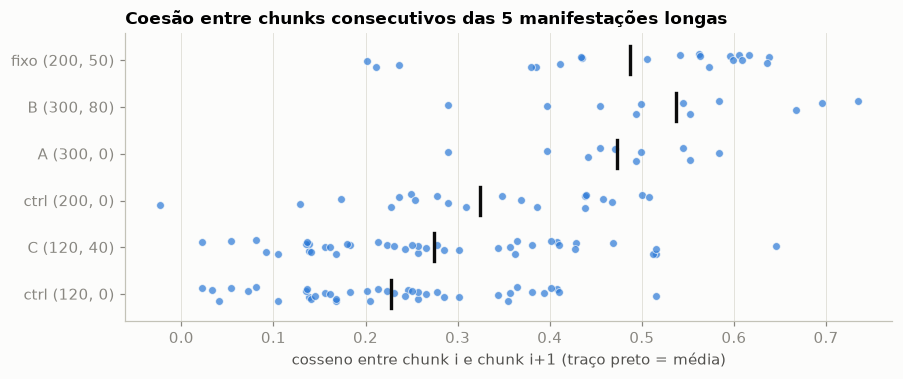

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ordem_cfg = ["ctrl (120, 0)", "C (120, 40)", "ctrl (200, 0)", "A (300, 0)", "B (300, 80)", "fixo (200, 50)"]
for y, nome_cfg in enumerate(ordem_cfg):
    sub = chunks[chunks.config == nome_cfg]
    valores = np.concatenate([oc.chunks_consecutivos_similaridade(EMB_CHUNKS[g.index]) for _, g in sub.groupby("id")])
    ax.scatter(valores, np.full_like(valores, y) + np.random.default_rng(0).uniform(-0.15, 0.15, len(valores)),
               s=26, color=oc.PALETA[0], alpha=0.7, edgecolor="#fcfcfb", linewidth=0.6)
    ax.plot([valores.mean()] * 2, [y - 0.3, y + 0.3], color="#0b0b0b", lw=2.2)
ax.set_yticks(range(len(ordem_cfg)), ordem_cfg)
ax.set_xlabel("cosseno entre chunk i e chunk i+1 (traço preto = média)")
ax.set_title("Coesão entre chunks consecutivos das 5 manifestações longas")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURAS / "e3_coesao.png")
plt.show()

**Resposta.** O overlap **aumenta** a coesão entre chunks vizinhos, porque parte do texto do chunk *i* está literalmente
no chunk *i+1*: a coesão média sobe de 0,47 para 0,54 de A (300, 0) para B (300, 80), e de 0,23 para 0,27 entre
(120, 0) e C (120, 40). Chunks maiores também são mais coesos entre si, porque cada um carrega mais contexto comum
(tema, local, narrador). Isso ajuda de duas formas: (i) uma frase que depende da anterior
("*Quando finalmente foi atendida, o médico pediu um raio-x, mas...*") não fica órfã do sujeito e do contexto; (ii) na
busca, um fato que cai na fronteira entre dois chunks aparece inteiro em pelo menos um deles.

Mas **mais coesão não é automaticamente melhor**. O controle "fixo (200, 50)" tem coesão alta (0,49) porque repete 50
caracteres entre vizinhos, e ao mesmo tempo corta palavras ao meio ("...disseram q" | "ete horas pelo atendimento...") e mistura o fim de um
fato com o começo de outro. A coesão ali é um artefato da redundância. O objetivo é chunks **internamente coerentes**
que se conectem bem aos vizinhos, e não chunks iguais entre si. Overlap também tem custo: mais chunks e mais texto
repetido para indexar e embutir.

## 4. Qual configuração preserva melhor o sentido das denúncias?

Além de ler os chunks, fazemos um **teste de busca**: para cada manifestação longa, escrevemos uma consulta sobre um
fato do **final** do texto (a parte que o modelo ignora quando a manifestação é indexada inteira). Comparamos a posição
da manifestação-alvo no ranking das 40 manifestações em dois cenários:

* **documento inteiro**: um embedding por manifestação (sistema atual);
* **chunks**: cada manifestação longa é representada pelos seus chunks, e o score dela é o **máximo** entre os chunks.

In [9]:
CONSULTAS = {
    "M006": "estacionamento da UPA escuro e sem vigia de madrugada",
    "M015": "transporte escolar atrasa e os alunos perdem a primeira aula",
    "M024": "córrego transborda na chuva e a água suja invade as ruas",
    "M034": "pedido de câmeras de monitoramento e base da guarda municipal no bairro",
    "M040": "lama da obra entupindo os bueiros e comércio perdendo clientes",
}
emb_consultas = oc.gerar_embeddings(modelo, list(CONSULTAS.values()), NOME_MODELO)
emb_docs = oc.gerar_embeddings(modelo, df["texto"].tolist(), NOME_MODELO)
ids = df["id"].tolist()

def ranking(score_por_id, alvo):
    ordenado = sorted(score_por_id, key=score_por_id.get, reverse=True)
    return ordenado.index(alvo) + 1, score_por_id[alvo]

linhas = []
for (alvo, consulta), q in zip(CONSULTAS.items(), emb_consultas):
    scores_doc = dict(zip(ids, emb_docs @ q))
    linha = {"alvo": alvo, "consulta": consulta}
    pos, s = ranking(scores_doc, alvo)
    linha["doc inteiro"] = f"{pos}º ({s:.2f})"
    for nome_cfg in ["A (300, 0)", "B (300, 80)", "C (120, 40)"]:
        sub = chunks[chunks.config == nome_cfg]
        scores = dict(scores_doc)
        for id_longa, g in sub.groupby("id"):          # manifestação longa -> máximo dos seus chunks
            scores[id_longa] = float((EMB_CHUNKS[g.index] @ q).max())
        pos, s = ranking(scores, alvo)
        linha[nome_cfg] = f"{pos}º ({s:.2f})"
    linhas.append(linha)
teste_busca = pd.DataFrame(linhas).set_index("alvo")
teste_busca

,consulta,doc inteiro,"A (300, 0)","B (300, 80)","C (120, 40)"
alvo,,,,,
M006,estacionamento da UPA escuro e sem vigia de madrugada,31º (0.19),14º (0.39),25º (0.27),1º (0.79)
M015,transporte escolar atrasa e os alunos perdem a primeira aula,4º (0.54),3º (0.67),3º (0.67),1º (0.90)
M024,córrego transborda na chuva e a água suja invade as ruas,1º (0.65),1º (0.78),1º (0.78),1º (0.91)
M034,pedido de câmeras de monitoramento e base da guarda municipal no bairro,3º (0.43),1º (0.85),1º (0.85),1º (0.85)
M040,lama da obra entupindo os bueiros e comércio perdendo clientes,1º (0.42),1º (0.55),1º (0.55),1º (0.49)


E qual chunk respondeu a cada consulta na configuração B?

In [10]:
sub = chunks[chunks.config == "B (300, 80)"]
for (alvo, consulta), q in zip(CONSULTAS.items(), emb_consultas):
    g = sub[sub.id == alvo]
    scores = EMB_CHUNKS[g.index] @ q
    melhor = g.iloc[int(np.argmax(scores))]
    print(f"{alvo} | consulta: {consulta}\n      chunk {melhor.ordem} ({scores.max():.2f}): {melhor.chunk}\n")

M006 | consulta: estacionamento da UPA escuro e sem vigia de madrugada
      chunk 2 (0.27): Os banheiros estavam imundos, sem papel e sem sabonete. Quando finalmente foi atendida, o médico pediu um raio-x, mas o aparelho estava quebrado e tivemos que ir a um laboratório particular. Na volta, já de madrugada, o estacionamento estava sem iluminação e sem nenhum vigia. Exijo providências.

M015 | consulta: transporte escolar atrasa e os alunos perdem a primeira aula
      chunk 2 (0.67): Os banheiros femininos estão interditados, com vasos quebrados. Além disso, o transporte escolar chega sempre atrasado e as crianças perdem a primeira aula. Pedimos uma vistoria da Secretaria de Educação.

M024 | consulta: córrego transborda na chuva e a água suja invade as ruas
      chunk 3 (0.78): Quando chove forte, o córrego transborda e a água suja invade as ruas mais baixas. Pedimos fiscalização ambiental, limpeza das margens e punição para os responsáveis.

M034 | consulta: pedido de câmeras de m

### 4.1 Os chunks "migram" de assunto

Uma manifestação longa não é homogênea. Para cada chunk da configuração B, procuramos a manifestação **curta** mais
parecida da base. Se a categoria dela for diferente da categoria da manifestação de origem, o chunk fala de outro assunto.

In [11]:
ids_curtas = [i for i in ids if i not in set(longas.id)]
idx_curtas = [ids.index(i) for i in ids_curtas]
linhas = []
for k, c in sub.iterrows():
    sims = emb_docs[idx_curtas] @ EMB_CHUNKS[k]
    j = int(np.argmax(sims))
    vizinho = df.iloc[idx_curtas[j]]
    linhas.append({"chunk": f"{c.id}[{c.ordem}]", "categoria de origem": c.categoria,
                   "início do chunk": c.chunk[:70] + "…", "vizinho mais próximo": vizinho.id,
                   "categoria do vizinho": vizinho.categoria_oficial, "cos": sims[j]})
migracao = pd.DataFrame(linhas)
migracao["mudou de categoria?"] = np.where(migracao["categoria de origem"] != migracao["categoria do vizinho"], "sim", "")
print(f"{(migracao['mudou de categoria?'] == 'sim').sum()} de {len(migracao)} chunks têm como vizinho mais próximo uma manifestação de OUTRA categoria")
migracao.style.format({"cos": "{:.2f}"}).hide(axis="index")

3 de 16 chunks têm como vizinho mais próximo uma manifestação de OUTRA categoria


chunk,categoria de origem,início do chunk,vizinho mais próximo,categoria do vizinho,cos,mudou de categoria?
M006[0],saúde,Quero registrar uma reclamação grave sobre a UPA do Centro. No sábado …,M039,saúde,0.66,
M006[1],saúde,"Ela ficou sentada numa cadeira de plástico no corredor, porque não hav…",M007,meio ambiente,0.35,sim
M006[2],saúde,"Os banheiros estavam imundos, sem papel e sem sabonete. Quando finalme…",M022,saúde,0.49,
M015[0],educação,Sou mãe de dois alunos da Escola Municipal Paulo Freire e escrevo para…,M004,educação,0.50,
M015[1],educação,As salas não têm ventilador e no verão a temperatura passa dos 35 grau…,M038,educação,0.48,
M015[2],educação,"Os banheiros femininos estão interditados, com vasos quebrados. Além d…",M038,educação,0.57,
M024[0],meio ambiente,"Venho denunciar a situação do córrego Água Limpa, que passa atrás do b…",M007,meio ambiente,0.63,
M024[1],meio ambiente,O mau cheiro é tão forte que à tarde não dá para ficar no quintal. Na …,M007,meio ambiente,0.53,
M024[2],meio ambiente,Na semana passada apareceram muitos peixes mortos boiando perto da pon…,M037,meio ambiente,0.56,
M024[3],meio ambiente,"Quando chove forte, o córrego transborda e a água suja invade as ruas …",M025,infraestrutura,0.50,sim


## 5. Visualização dos chunks no espaço 2D

Projetamos juntos os chunks da configuração B, os embeddings das 5 manifestações longas inteiras (estrelas) e as 35
manifestações curtas (pontos cinza, como referência do "mapa" de assuntos). Linhas finas ligam chunks consecutivos da
mesma manifestação, mostrando o "percurso" da narrativa.

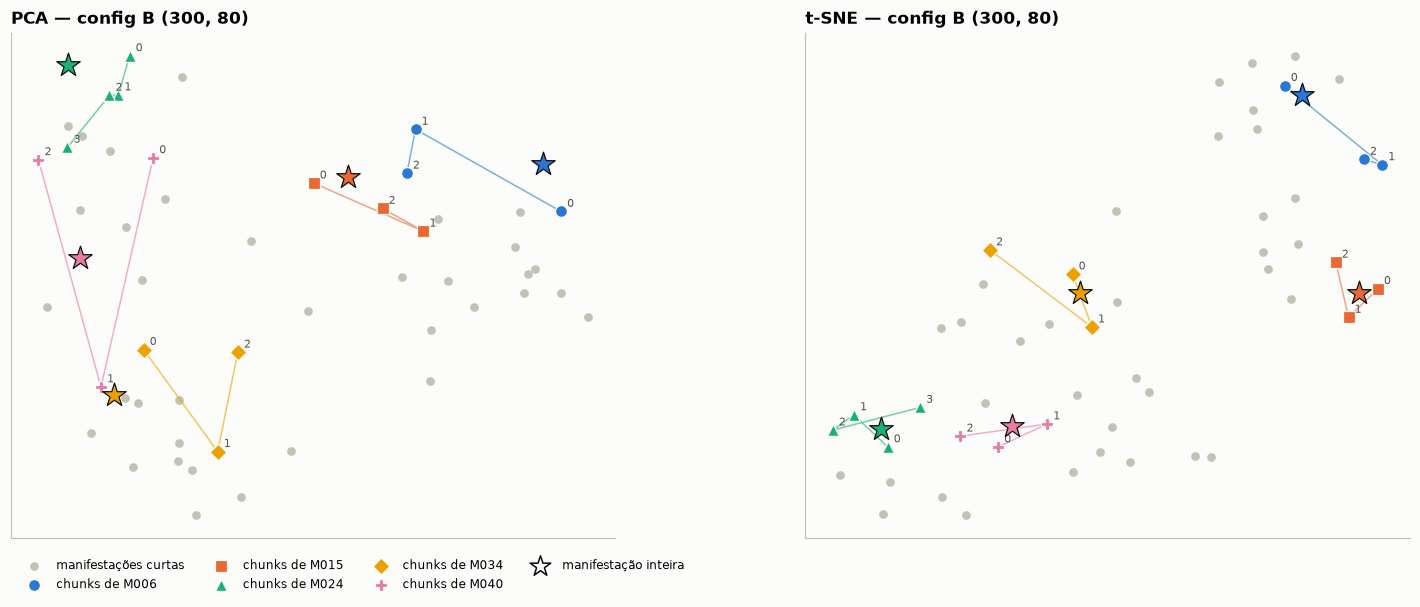

In [12]:
def plot_chunks_2d(nome_cfg, arquivo):
    sub = chunks[chunks.config == nome_cfg]
    idx_longas = [ids.index(i) for i in longas.id]
    X = np.vstack([EMB_CHUNKS[sub.index], emb_docs[idx_longas], emb_docs[idx_curtas]])
    n_ch, n_lg = len(sub), len(idx_longas)

    projecoes = {
        "PCA": PCA(n_components=2, random_state=42).fit_transform(X),
        "t-SNE": TSNE(n_components=2, perplexity=12, metric="cosine", init="pca", random_state=42).fit_transform(X),
    }
    fig, eixos = plt.subplots(1, 2, figsize=(13, 5.6))
    for ax, (metodo, P) in zip(eixos, projecoes.items()):
        ax.scatter(P[n_ch + n_lg:, 0], P[n_ch + n_lg:, 1], s=22, color="#c3c2b7", label="manifestações curtas")
        for cor_k, (id_longa, marcador) in enumerate(zip(longas.id, ["o", "s", "^", "D", "P"])):
            pos_g = np.where(sub["id"].to_numpy() == id_longa)[0]
            cor = oc.PALETA[cor_k]
            ax.plot(P[pos_g, 0], P[pos_g, 1], color=cor, lw=1, alpha=0.6)
            ax.scatter(P[pos_g, 0], P[pos_g, 1], s=60, color=cor, marker=marcador, edgecolor="#fcfcfb",
                       linewidth=0.8, label=f"chunks de {id_longa}", zorder=3)
            for p_i, o in zip(pos_g, sub["ordem"].to_numpy()[pos_g]):
                ax.annotate(str(o), P[p_i], xytext=(4, 3), textcoords="offset points", fontsize=7, color="#52514e")
            ax.scatter(*P[n_ch + cor_k], s=260, marker="*", color=cor, edgecolor="#0b0b0b", linewidth=0.8, zorder=4)
        ax.set_title(f"{metodo} — config {nome_cfg}")
        ax.set_xticks([]); ax.set_yticks([])
    eixos[0].scatter([], [], s=200, marker="*", color="#ffffff", edgecolor="#0b0b0b", label="manifestação inteira")
    eixos[0].legend(loc="upper left", bbox_to_anchor=(0, -0.02), ncol=4, fontsize=8)
    fig.tight_layout()
    fig.savefig(FIGURAS / arquivo)
    plt.show()

plot_chunks_2d("B (300, 80)", "e3_chunks_2d_B.png")

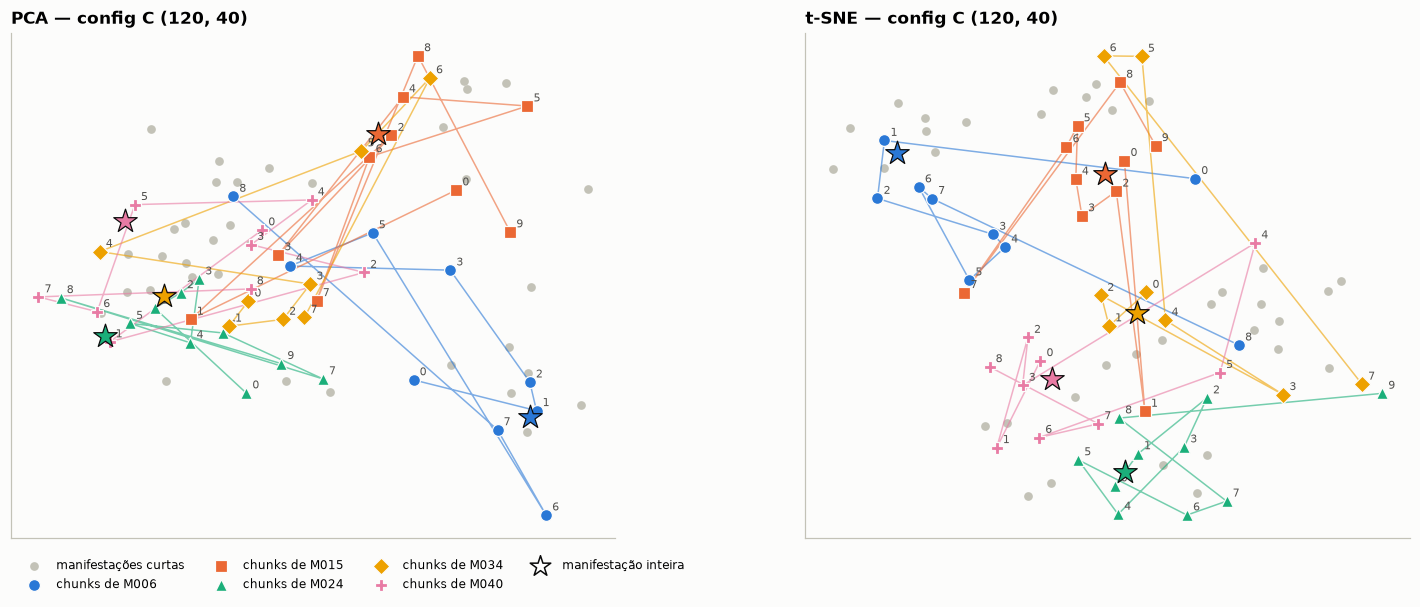

In [13]:
plot_chunks_2d("C (120, 40)", "e3_chunks_2d_C.png")

Para não depender só da impressão visual (PCA e t-SNE distorcem distâncias), comparamos a similaridade média **entre
chunks da mesma manifestação** e **entre chunks de manifestações diferentes**, no espaço original de 384 dimensões:

In [14]:
linhas = []
for nome_cfg in ["C (120, 40)", "A (300, 0)", "B (300, 80)"]:
    sub_c = chunks[chunks.config == nome_cfg]
    S = EMB_CHUNKS[sub_c.index] @ EMB_CHUNKS[sub_c.index].T
    mesma = sub_c["id"].to_numpy()[:, None] == sub_c["id"].to_numpy()[None, :]
    fora_diag = ~np.eye(len(sub_c), dtype=bool)
    linhas.append({"config": nome_cfg,
                   "cos médio — mesma manifestação": S[mesma & fora_diag].mean(),
                   "cos médio — manifestações diferentes": S[~mesma].mean(),
                   "silhueta": silhouette_score(EMB_CHUNKS[sub_c.index], sub_c["id"], metric="cosine")})
pd.DataFrame(linhas).set_index("config").style.format("{:.3f}")

,cos médio — mesma manifestação,cos médio — manifestações diferentes,silhueta
config,,,
"C (120, 40)",0.261,0.152,0.049
"A (300, 0)",0.481,0.277,0.172
"B (300, 80)",0.513,0.285,0.206


## 6. Respostas e conclusão

**Como o overlap influencia a coesão semântica entre chunks consecutivos?**
O overlap aumenta a similaridade entre chunks vizinhos (A → B: 0,47 → 0,54; 120/0 → 120/40: 0,23 → 0,27), porque
repete o final de um no começo do outro. Frases que dependem do contexto anterior deixam de ficar órfãs, e um fato que
cai na fronteira aparece inteiro em pelo menos um chunk. Há três ressalvas. (i) No `RecursiveCharacterTextSplitter`
o overlap é feito com **unidades inteiras** (frases, orações), e não com caracteres, então pode não ter efeito nenhum:
(200, 0) e (200, 50) geraram chunks idênticos. (ii) Coesão demais é redundância: o corte fixo com overlap tem coesão
alta, mas corta palavras e mistura fatos. (iii) O overlap também pode **diluir** um fato. Em B, o chunk final do M006
recebeu a frase dos banheiros e ficou menos focado no estacionamento do que em A (a busca por esse fato caiu do 14º para
o 25º lugar).

**Qual configuração preserva melhor o sentido das denúncias?**
Depende do que "sentido" significa para o uso. Os resultados mostram um *trade-off* claro:

| | A (300, 0) | **B (300, 80)** | C (120, 40) |
|---|---|---|---|
| Chunks que terminam em fim de frase | 100% | **100%** | 74% |
| Silhueta (chunks agrupados por manifestação) | 0,17 | **0,21** | 0,05 |
| Consultas em que o alvo ficou em 1º lugar | 3 de 5 | 3 de 5 | **5 de 5** |

* Como **unidade de denúncia**, para ler, rotear para a secretaria ou agrupar, a **B (300, 80)** preserva melhor o
  sentido. Os chunks são frases completas agrupadas em 1–3 fatos relacionados (ex.: "*Os banheiros estavam imundos... Quando
  finalmente foi atendida, o médico pediu um raio-x, mas o aparelho estava quebrado...*"), cada um se sustenta sozinho e
  todos cabem nos 128 tokens. Ela também tem a maior silhueta e a maior coesão entre as recursivas.
* Para **encontrar um fato específico**, a **C (120, 40)** é a melhor: colocou as 5 manifestações-alvo em 1º lugar,
  inclusive o estacionamento do M006, que no documento inteiro ficava em 31º. O custo é produzir fragmentos sem sujeito
  ("*o médico pediu um raio-x, mas o aparelho estava quebrado...*", "*porque não havia maca disponível, e o soro...*")
  e o triplo de chunks.
* O corte fixo é o pior nos dois critérios: quebra palavras e 80% dos chunks terminam no meio de uma frase.

**Recomendação:** o padrão *small-to-big*. A busca é feita sobre **chunks pequenos** (C), e o resultado é mostrado com o
contexto maior (o chunk B ou a manifestação inteira, com o trecho encontrado destacado). O app implementa essa ideia:
a busca compara a consulta com os chunks das manifestações longas, usa o **máximo** como score e mostra o texto
completo com o trecho que casou em destaque.

**Os chunks de uma mesma manifestação ficam próximos no espaço 2D?**
**Na configuração B, sim, em geral.** No t-SNE os chunks de cada manifestação ficam em torno do embedding do documento
inteiro (estrela). No PCA, que preserva só as 2 direções de maior variância, eles se espalham mais: o chunk de abertura
do M006, sobre a espera na UPA, fica longe dos chunks sobre maca, banheiros e estacionamento. **Na configuração C, não:**
os fragmentos se espalham pelo mapa todo e a silhueta cai para 0,05, porque orações curtas carregam pouco contexto do
todo. A análise de vizinhos mostra ainda que **3 dos 16 chunks de B têm como vizinho mais próximo uma manifestação de
outra categoria**. O trecho do M034 sobre viatura que não passa e **postes apagados** fica mais perto do M005 (poste
apagado, infraestrutura), e o trecho do M024 sobre o córrego que **transborda e invade as ruas** fica mais perto do M025
(buraco que piora com a chuva, infraestrutura). Isso não é defeito do chunking. É a informação que o embedding do
documento inteiro escondia: uma manifestação longa pode conter **mais de uma demanda, para mais de uma secretaria**.